# 03. v2 prior (1) — 그래프, 간선, 초기 데이터

PFN의 성능은 prior가 정합니다. TabPFN v2는 v1의 SCM prior를 크게 바꿔, 실제 표 데이터에 흔한 범주형 feature, 결측값, 무의미한 feature, 계단 모양 관계까지 합성 데이터셋에 넣었습니다(논문 Fig. 2, Methods의 "Details on the causal generative process"). 이 노트북과 다음 노트북은 그 생성 과정을 작은 예부터 따라가며 직접 만들어 봅니다. 이 노트북은 그래프를 뽑고 노드마다 값을 계산하는 데까지(그래프, 간선 함수, 원인 노드의 초기 데이터)이고, 그 값을 표로 읽고 다듬어 데이터셋을 뽑는 것은 [04 v2 prior (2) — 그래프에서 표로](04_prior_from_graph_to_table.ipynb)에서 봅니다.

두 가지를 먼저 밝혀 둡니다.

- 논문은 prior 생성 코드를 공개하지 않았습니다(*"The code to generate synthetic pre-training data has not been released with our models"*). Methods에 절차는 있지만 하이퍼파라미터의 분포와 수치는 없습니다. 그래서 이 노트북의 수치는 설명용으로 정한 값이고, 논문에 없는 세부를 정한 곳에는 "여기서 정함"이라고 적었습니다.
- 이 저장소에서 v2를 학습할 때는 공개된 TabICL prior를 씁니다([04 v2 prior (2) — 그래프에서 표로](04_prior_from_graph_to_table.ipynb) 5절). 두 노트북은 논문의 prior가 어떤 생각으로 만들어졌는지 이해하는 것이 목적입니다.

SCM 자체는 [`02_tabpfn/01_scm_primer`](../02_tabpfn/01_scm_primer.ipynb)에서 다뤘습니다.

다루는 흐름:

1. v1 prior와 무엇이 다른가
2. 그래프 뽑기 — growing network with redirection
3. 노드는 벡터, 간선은 함수
4. 원인 노드의 초기 데이터
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# rng = random number generator(난수 생성기). 모든 무작위 값을 여기서 뽑는다.
rng = np.random.default_rng(0)

## 1. v1 prior와 무엇이 다른가

![TabPFN v2 Figure 2](images/tabpfn_v2_fig2.png)

*그림: 논문 Fig. 2 (Hollmann et al. 2025, [Nature 637:319](https://doi.org/10.1038/s41586-024-08328-6), CC BY 4.0). (a) 데이터셋마다 행 수, feature 수, 노드 수, 그래프 복잡도를 뽑고 그래프를 뽑습니다. (b) 1: 초기 데이터를 그래프에 흘려 보냅니다. 2·3: feature(F)와 target(T) 노드를 골라 그 자리의 값을 읽습니다. 4: 후처리합니다. 아래는 간선의 세 종류(신경망, 나무, 이산화)입니다. (c) 이렇게 만든 데이터셋들입니다.*

v1 prior와 비교하면 다음과 같습니다.

| | v1 (2023) | v2 (2025) | 이 노트북 |
|---|---|---|---|
| 그래프 | 층을 쌓은 MLP 모양, 간선을 무작위로 지움 | scale-free 그래프(growing network with redirection), 여러 조각을 합치기도 함 | 2절 |
| 노드 값 | 숫자 하나 | 벡터 하나 ($\mathbb{R}^d$) | 3절 |
| 간선 | 선형 + 활성화 함수 | 작은 신경망(활성화 함수 12종), 결정 나무, 이산화, 노이즈 | 3절 |
| 원인 노드 입력 | 정규분포 | 정규·균등·혼합, 행끼리 닮게 만들기도 함 | 4절 |
| 범주형 feature | 일부 열을 구간 번호로 바꿈 | 그래프 안에서 이산화한 노드를 그대로 읽음 | 3절, 04의 1절 |
| target | 연속값을 경계로 잘라 클래스로 | 분류: 범주형 노드, 회귀: 연속값 노드 | 04의 1절 |
| 후처리 | 표준화, 이상치 누르기 | Kumaraswamy 휘기, 구간 나누기, 결측값 | 04의 2절 |
| BNN prior | SCM과 반씩 섞음 | 없음 | |

## 2. 그래프 뽑기 — growing network with redirection

v2는 그래프를 growing network with redirection(GNR, Krapivsky & Redner 2001)으로 뽑습니다. 노드를 하나씩 추가하면서 기존 노드에 이어 붙이는 방법입니다.

1. 노드 0 하나로 시작합니다.
2. 새 노드 $t$가 올 때마다 기존 노드 하나를 고르게 고릅니다.
3. 확률 $P$로 "방향을 바꿉니다(redirection)". 고른 노드 대신, 고른 노드가 이어 붙었던 노드에 붙습니다.
4. 새 노드와 붙은 노드를 간선으로 잇습니다.

3번 때문에 이미 많이 붙은 노드가 더 자주 선택됩니다. 많이 붙은 노드일수록 "고른 노드가 이어 붙었던 노드"로 자주 등장하기 때문입니다. 그래서 간선이 몇몇 노드(hub)에 몰리는 scale-free 그래프가 됩니다. 노드 수 $N$은 로그 균등분포에서, $P$는 감마분포에서 뽑습니다(논문).

간선 방향은 논문에 없어서 여기서 정했습니다. 새 노드 → 붙은 노드, 즉 나중에 생긴 노드를 원인으로 둡니다. 그러면 원인 노드(부모가 없는 노드)가 여럿 생기고, hub는 원인이 많이 모이는 노드가 됩니다.

노드 6개로 먼저 따라가 봅니다.

In [3]:
def sample_gnr_graph(n_nodes, p_redirect, rng):
    attached_to = {0: None}  # attached_to[t] = 새 노드 t가 이어 붙은 기존 노드
    steps = []
    for t in range(1, n_nodes):
        picked = int(rng.integers(0, t))  # 2. 기존 노드 하나를 고르게 고른다
        can_redirect = attached_to[picked] is not None  # 노드 0은 붙은 노드가 없다
        redirected = can_redirect and rng.random() < p_redirect  # 3. 확률 P로 방향을 바꾼다
        if redirected:
            attach = attached_to[picked]
        else:
            attach = picked
        attached_to[t] = attach  # 4. t → attach 간선
        steps.append(
            {"새 노드": t, "고른 노드": picked, "방향 바꿈": redirected, "붙은 노드": attach}
        )
    # 간선 t → attached_to[t]: t가 원인, attached_to[t]가 결과
    parents = {u: [t for t in range(n_nodes) if attached_to[t] == u] for u in range(n_nodes)}
    return parents, steps


parents, steps = sample_gnr_graph(6, p_redirect=0.5, rng=np.random.default_rng(3))
display(pd.DataFrame(steps))
display(pd.DataFrame({"부모(원인)": {u: pa for u, pa in parents.items()}}))

,새 노드,고른 노드,방향 바꿈,붙은 노드
0,1,0,False,0
1,2,1,True,0
2,3,0,False,0
3,4,0,False,0
4,5,4,False,4


,부모(원인)
0,"[1, 2, 3, 4]"
1,[]
2,[]
3,[]
4,[5]
5,[]


그래프를 그릴 때는 원인 노드를 왼쪽에, 결과 쪽 노드를 오른쪽에 둡니다. 노드 0은 모든 간선이 결국 모이는 곳이라 맨 오른쪽입니다.

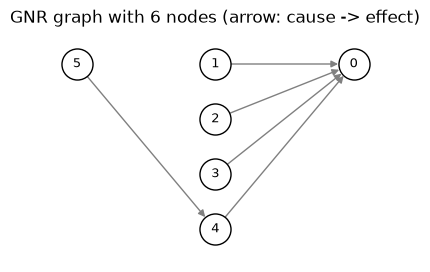

In [4]:
def layout(parents):
    # 노드 0에서 거슬러 올라간 거리를 x 위치로 쓴다 (원인일수록 왼쪽)
    child_of = {t: u for u, pa in parents.items() for t in pa}
    depth = {}
    for node in sorted(parents):
        d, cur = 0, node
        while cur in child_of:
            cur, d = child_of[cur], d + 1
        depth[node] = d
    pos, used = {}, {}
    for node in sorted(parents):
        level = depth[node]
        pos[node] = (-level, -used.get(level, 0))
        used[level] = used.get(level, 0) + 1
    return pos


def draw_graph(ax, parents, colors=None, labels=None, node_size=500, title=None):
    colors = colors or {}
    labels = labels or {node: str(node) for node in parents}
    pos = layout(parents)
    shrink = np.sqrt(node_size) / 2
    for child, pa in parents.items():
        for parent in pa:
            ax.annotate(
                "",
                xy=pos[child],
                xytext=pos[parent],
                arrowprops=dict(
                    arrowstyle="-|>", color="gray", lw=1, shrinkA=shrink, shrinkB=shrink
                ),
            )
    for node, (x, y) in pos.items():
        ax.scatter(x, y, s=node_size, color=colors.get(node, "white"), edgecolor="black", zorder=3)
        ax.text(x, y, labels.get(node, ""), ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(title or "")
    ax.margins(0.2)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(5, 3))
draw_graph(ax, parents, title="GNR graph with 6 nodes (arrow: cause -> effect)")
plt.show()

간선 수는 항상 노드 수 − 1이고, 노드마다 자식(결과)이 하나뿐인 나무 모양입니다. 논문은 $P$가 작을수록 간선이 많은 조밀한 그래프가 된다고 적었는데, 원래 GNR은 간선 수가 일정하므로 논문 구현은 GNR을 어떤 식으로든 바꿨을 것입니다. 그 방법은 알 수 없어서, 여기서는 원래 GNR을 쓰고 $P$가 hub의 크기를 바꾸는 것만 봅니다. 노드 200개짜리 그래프에서 부모 수(들어오는 간선 수)를 셉니다.

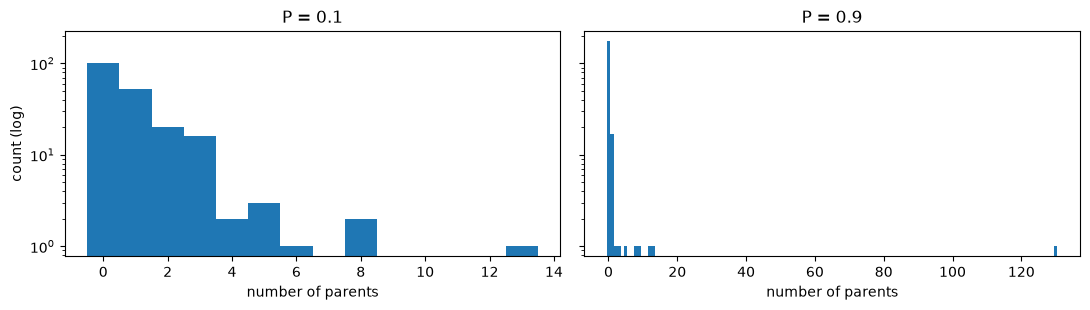

,P,원인 노드(부모 0개) 비율,가장 큰 hub의 부모 수
0,0.1,51%,13
1,0.9,88%,130


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
rows = []
for ax, p in zip(axes, [0.1, 0.9], strict=True):
    big, _ = sample_gnr_graph(200, p_redirect=p, rng=np.random.default_rng(0))
    n_parents = np.array([len(pa) for pa in big.values()])
    ax.hist(n_parents, bins=np.arange(-0.5, n_parents.max() + 1.5), color="C0")
    ax.set_yscale("log")
    ax.set_xlabel("number of parents")
    ax.set_title(f"P = {p}")
    rows.append(
        {
            "P": p,
            "원인 노드(부모 0개) 비율": f"{np.mean(n_parents == 0):.0%}",
            "가장 큰 hub의 부모 수": int(n_parents.max()),
        }
    )
axes[0].set_ylabel("count (log)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

$P$가 크면 방향 바꾸기가 잦아서 소수의 hub에 원인이 몰립니다. 어느 쪽이든 노드의 절반 이상이 원인 노드입니다.

논문은 그래프 하나를 쓰거나, 따로 뽑은 그래프 여러 개를 합쳐 쓴다고 적었습니다. 합친 그래프에서 target과 다른 조각에 있는 feature는 target과 아무 관계가 없습니다. 실제 표에 흔한 무의미한 feature를 이렇게 만듭니다.

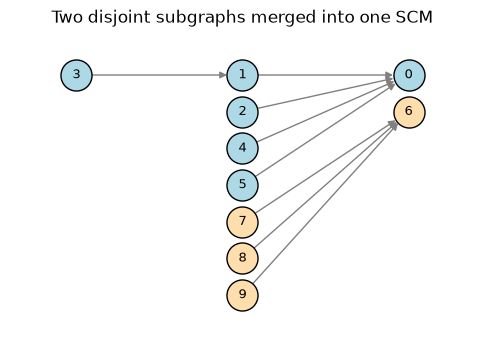

In [6]:
def merge_graphs(graphs):
    # 조각마다 노드 번호를 겹치지 않게 밀어서 합친다
    merged, offset, component = {}, 0, {}
    for k, g in enumerate(graphs):
        for u, pa in g.items():
            merged[u + offset] = [t + offset for t in pa]
            component[u + offset] = k
        offset += len(g)
    return merged, component


g1, _ = sample_gnr_graph(6, 0.5, np.random.default_rng(1))
g2, _ = sample_gnr_graph(4, 0.5, np.random.default_rng(2))
merged, component = merge_graphs([g1, g2])

fig, ax = plt.subplots(figsize=(6, 4))
draw_graph(
    ax,
    merged,
    colors={u: ("lightblue" if k == 0 else "navajowhite") for u, k in component.items()},
    title="Two disjoint subgraphs merged into one SCM",
)
plt.show()

## 3. 노드는 벡터, 간선은 함수

v1에서는 노드 값이 숫자 하나였습니다. v2에서는 노드 값이 길이 $d$인 벡터입니다. 간선마다 부모의 벡터를 자식의 벡터로 바꾸는 함수가 하나씩 있고, 함수의 종류는 논문 Fig. 2b 아래의 세 가지입니다.

- **작은 신경망**: $\sigma(Wx + b)$. $W$는 Xavier 초기화로 뽑고, 활성화 함수 $\sigma$는 identity, log, sigmoid, 절댓값, sin, tanh, 순위(rank), 제곱, 거듭제곱, smooth ReLU, 계단, 나머지(modulo) 중 하나입니다.
- **결정 나무**: 입력 벡터의 좌표 몇 개에 문턱값을 두고, 어느 잎에 떨어지느냐로 출력 벡터를 정합니다. 규칙 기반의 계단 모양 관계를 만듭니다.
- **이산화**: 벡터를 미리 뽑아 둔 대표 벡터 $K$개 중 가장 가까운 것의 번호로 바꿉니다. 이 번호가 범주형 feature가 됩니다. 그래프 안에서 계속 쓰려면 번호마다 따로 뽑은 임베딩 벡터로 바꿔 흘려 보냅니다.

모든 간선은 마지막에 정규분포 노이즈 $\mathcal{N}(0, \sigma^2 I)$를 더합니다. 행 하나($d = 3$)로 각 함수를 따라가 봅니다. 먼저 활성화 함수들입니다.

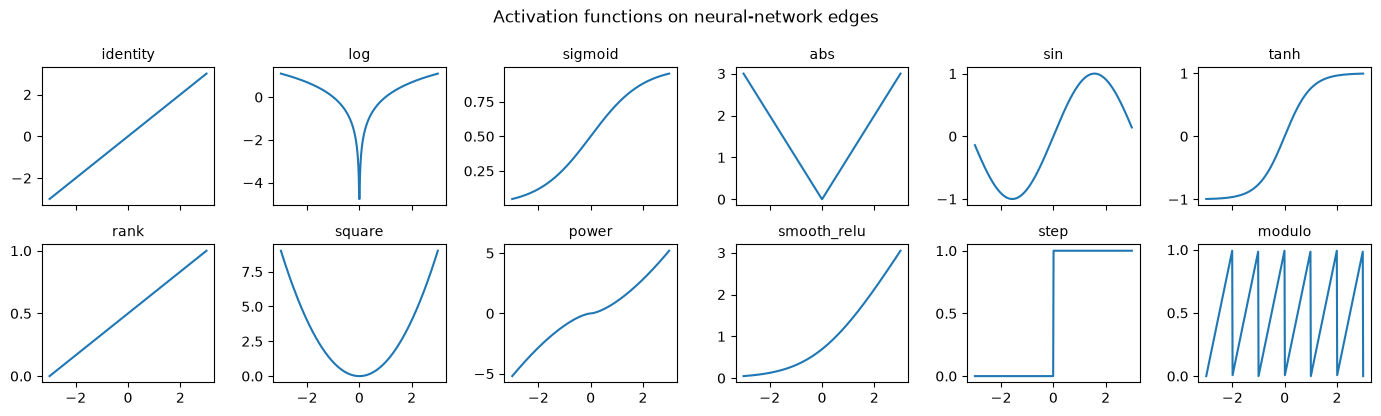

In [7]:
def rank(v):
    # 순위 변환: 같은 좌표의 행들 사이에서 몇 번째로 작은지 (0~1)
    return np.argsort(np.argsort(v, axis=0), axis=0) / max(len(v) - 1, 1)


ACTIVATIONS = {
    "identity": lambda v: v,
    "log": lambda v: np.log(np.abs(v) + 1e-3),
    "sigmoid": lambda v: 1 / (1 + np.exp(-v)),
    "abs": np.abs,
    "sin": np.sin,
    "tanh": np.tanh,
    "rank": rank,
    "square": np.square,
    "power": lambda v: np.sign(v) * np.abs(v) ** 1.5,
    "smooth_relu": lambda v: np.log1p(np.exp(v)),
    "step": lambda v: (v > 0).astype(float),
    "modulo": lambda v: np.mod(v, 1.0),
}

grid = np.linspace(-3, 3, 400)[:, None]
fig, axes = plt.subplots(2, 6, figsize=(14, 4.2), sharex=True)
for ax, (name, f) in zip(axes.flat, ACTIVATIONS.items(), strict=True):
    ax.plot(grid[:, 0], f(grid)[:, 0], color="C0")
    ax.set_title(name, fontsize=10)
fig.suptitle("Activation functions on neural-network edges")
plt.tight_layout()
plt.show()

계단과 나머지 함수는 매끄럽지 않은 관계를, 순위 함수는 값의 크기 대신 순서만 남기는 관계를 만듭니다. v1의 활성화 함수 3종(tanh, identity, ReLU)보다 훨씬 다양합니다.

이제 행 하나의 부모 벡터 $x = [0.5, -1.0, 0.3]$이 세 종류의 간선을 지나는 과정을 단계별로 봅니다. **신경망 간선**부터입니다.

In [8]:
d = 3
x = np.array([[0.5, -1.0, 0.3]])  # 부모 노드의 벡터 (행 1개)

edge_rng = np.random.default_rng(7)
limit = np.sqrt(6 / (d + d))  # Xavier 균등 초기화의 범위
W = edge_rng.uniform(-limit, limit, (d, d))
b = edge_rng.normal(0, 0.5, d)

# 1단계: 선형 변환
linear = x @ W.T + b
# 2단계: 활성화 함수 (여기서는 sin)
out = ACTIVATIONS["sin"](linear)

display(
    pd.DataFrame(
        {"부모 x": x[0], "Wx + b": linear[0], "sin(Wx + b)": out[0]},
        index=[f"좌표 {i}" for i in range(d)],
    ).round(3)
)

,부모 x,Wx + b,sin(Wx + b)
좌표 0,0.5,-0.814,-0.727
좌표 1,-1.0,0.594,0.560
좌표 2,0.3,-0.781,-0.704


**결정 나무 간선**은 깊이 2짜리 나무로 봅니다. 뿌리에서 좌표 하나를 문턱값과 비교해 왼쪽·오른쪽으로 가고, 거기서 다른 좌표로 한 번 더 갈라 잎 4개 중 하나에 도착합니다. 잎마다 출력 벡터가 정해져 있습니다. 갈림길이 보는 좌표와 문턱값, 잎의 출력은 간선마다 무작위로 뽑습니다.

In [9]:
split_dims = [0, 2, 1]  # 뿌리, 왼쪽 갈림길, 오른쪽 갈림길이 보는 좌표
thresholds = [0.2, 0.0, -0.5]
leaves = np.round(edge_rng.normal(0, 1, (4, d)), 2)  # 잎 4개의 출력 벡터

# 1단계: 뿌리 — 좌표 0이 0.2보다 큰가?
go_right = x[0, split_dims[0]] > thresholds[0]
# 2단계: 오른쪽이면 좌표 1, 왼쪽이면 좌표 2를 본다
if go_right:
    second = x[0, split_dims[2]] > thresholds[2]
else:
    second = x[0, split_dims[1]] > thresholds[1]
# 3단계: 도착한 잎의 출력 벡터
leaf = 2 * int(go_right) + int(second)

print(f"뿌리: x[0] = {x[0, 0]} > {thresholds[0]} ? {go_right}")
print(f"둘째 갈림길: x[1] = {x[0, 1]} > {thresholds[2]} ? {second}")
print(f"도착한 잎: {leaf}, 출력 = {leaves[leaf]}")

뿌리: x[0] = 0.5 > 0.2 ? True
둘째 갈림길: x[1] = -1.0 > -0.5 ? False
도착한 잎: 2, 출력 = [-1.9  -1.29 -1.84]


**이산화**는 대표 벡터와의 거리를 재서 가장 가까운 것의 번호를 고릅니다. 대표 벡터 수 $K$는 반올림한 감마분포에 2를 더해 뽑습니다(최소 2개, 논문). 여기서는 $K = 3$입니다.

In [10]:
K = 3
prototypes = np.round(edge_rng.normal(0, 1, (K, d)), 2)  # 대표 벡터 p_1..p_K
embeddings = np.round(edge_rng.normal(0, 1, (K, d)), 2)  # 번호마다 그래프 안에서 쓸 벡터 p'_1..p'_K

# 1단계: 대표 벡터마다 거리
distance = np.sqrt(((x[0] - prototypes) ** 2).sum(axis=1))
# 2단계: 가장 가까운 대표 벡터의 번호 = 범주형 값
category = int(distance.argmin())
# 3단계: 그 번호의 임베딩 벡터를 자식 노드로 흘려 보낸다

display(
    pd.DataFrame(
        {"대표 벡터": [str(p) for p in prototypes], "x와의 거리": distance.round(3)},
        index=[f"범주 {k}" for k in range(K)],
    )
)
print(f"범주형 값 = {category}, 흘려 보내는 벡터 = {embeddings[category]}")

,대표 벡터,x와의 거리
범주 0,[ 0.16 -0.19 -2.52],2.954
범주 1,[-0.54 -0.05 0.11],1.421
범주 2,[-1.53 -0.48 -0.98],2.456


범주형 값 = 1, 흘려 보내는 벡터 = [-0.03  0.88 -0.58]


부모가 여럿인 노드에서 간선 출력을 어떻게 합치는지는 논문에 없습니다. 여기서는 간선 출력을 더한 뒤 노이즈를 더하고, 값의 크기가 깊이에 따라 커지거나 작아지지 않도록 좌표마다 행들 사이에서 표준화합니다(여기서 정함). 또 이산화는 간선 대신 노드에 붙였습니다. 부모가 여럿이어도 범주형 값이 하나로 정해지게 하기 위해서입니다(여기서 정함).

In [11]:
def make_nn_edge(d, rng):
    limit = np.sqrt(6 / (d + d))
    W = rng.uniform(-limit, limit, (d, d))
    b = rng.normal(0, 0.5, d)
    act = ACTIVATIONS[rng.choice(list(ACTIVATIONS))]
    return lambda v: act(v @ W.T + b)


def make_tree_edge(d, rng):
    dims = rng.integers(0, d, size=3)
    cuts = rng.normal(0, 0.5, size=3)
    leaf_values = rng.normal(0, 1, size=(4, d))

    def edge(v):
        go_right = v[:, dims[0]] > cuts[0]
        second = np.where(go_right, v[:, dims[2]] > cuts[2], v[:, dims[1]] > cuts[1])
        return leaf_values[2 * go_right + second]

    return edge


def standardize(v):
    return (v - v.mean(axis=0)) / (v.std(axis=0) + 1e-8)

## 4. 원인 노드의 초기 데이터

원인 노드(부모가 없는 노드)에는 행마다 초기 데이터 $\epsilon$을 넣습니다. 세 가지 방식 중 하나입니다(논문).

- 정규: $\epsilon \sim \mathcal{N}(0, \sigma_\epsilon^2)$
- 균등: $\epsilon \sim U(-a, a)$
- 혼합: 원인 노드마다 정규와 균등 중 하나를 고름

일부 데이터셋에서는 행끼리 서로 닮게 만듭니다. 행의 일부($\rho n$개)를 "원형(prototype)" $x^*_1, \dots, x^*_M$으로 먼저 뽑고, 모든 행을 원형들의 가중 평균으로 만듭니다.

$$
x_i = \sum_{j=1}^{M} \alpha_{ij}\, x^*_j, \qquad \sum_j \alpha_{ij} = 1
$$

온도 $\beta$가 크면 가중치가 고르게 퍼지고, 작으면 원형 몇 개에 몰립니다. 논문은 가중치를 "Multinomial($\beta$)"에서 뽑는다고만 적어서, 여기서는 표준정규 난수를 $\beta$로 나눠 softmax한 값을 가중치로 씁니다(여기서 정함). 원형 3개, 행 2개로 가중치를 봅니다.

In [12]:
def prototype_weights(n_rows, n_prototypes, beta, rng):
    logits = rng.standard_normal((n_rows, n_prototypes)) / beta
    w = np.exp(logits - logits.max(axis=1, keepdims=True))
    return w / w.sum(axis=1, keepdims=True)  # 행마다 합이 1


for beta in [5.0, 0.2]:
    w = prototype_weights(2, 3, beta, np.random.default_rng(0))
    print(f"β = {beta}")
    display(
        pd.DataFrame(w, columns=["원형 1", "원형 2", "원형 3"], index=["행 1", "행 2"]).round(2)
    )

β = 5.0


,원형 1,원형 2,원형 3
행 1,0.33,0.31,0.36
행 2,0.34,0.30,0.36


β = 0.2


,원형 1,원형 2,원형 3
행 1,0.07,0.02,0.91
행 2,0.22,0.01,0.78


$\beta = 5$에서는 행마다 세 원형을 고르게 섞고, $\beta = 0.2$에서는 원형 하나를 거의 그대로 가져옵니다. 원인 노드 하나(2차원)의 초기 데이터 500행으로 차이를 그려 봅니다.

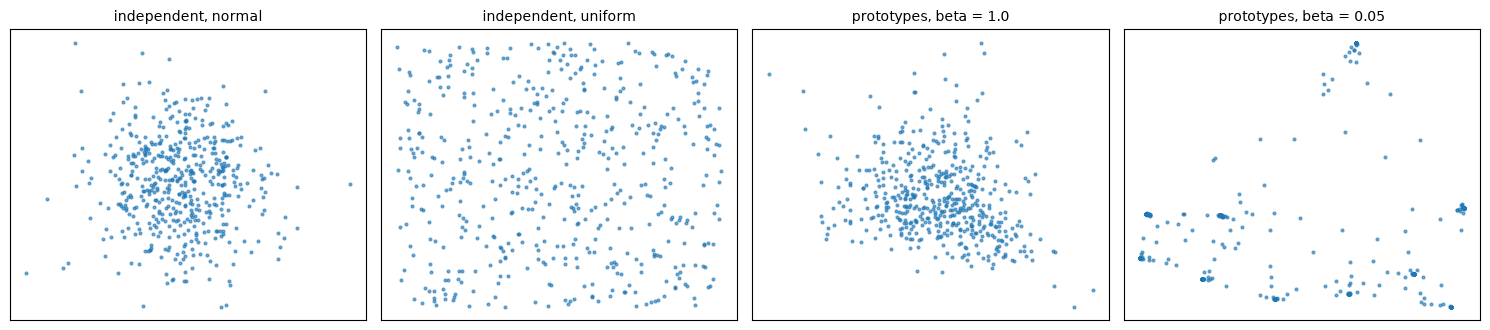

In [13]:
def sample_init(n_rows, width, rng, mode="normal", prototype_frac=None, beta=1.0):
    # 원인 노드들의 초기 데이터 (n_rows, width)
    def draw(n):
        if mode == "normal":
            return rng.normal(0, 1, (n, width))
        if mode == "uniform":
            return rng.uniform(-1.7, 1.7, (n, width))
        # mixed: 열마다 정규 또는 균등
        use_normal = rng.random(width) < 0.5
        return np.where(
            use_normal, rng.normal(0, 1, (n, width)), rng.uniform(-1.7, 1.7, (n, width))
        )

    if prototype_frac is None:
        return draw(n_rows)
    n_proto = max(2, round(prototype_frac * n_rows))
    prototypes = draw(n_proto)
    weights = prototype_weights(n_rows, n_proto, beta, rng)
    return weights @ prototypes


init_rng = np.random.default_rng(1)
settings = {
    "independent, normal": dict(mode="normal"),
    "independent, uniform": dict(mode="uniform"),
    "prototypes, beta = 1.0": dict(mode="normal", prototype_frac=0.02, beta=1.0),
    "prototypes, beta = 0.05": dict(mode="normal", prototype_frac=0.02, beta=0.05),
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (title, kw) in zip(axes, settings.items(), strict=True):
    eps = standardize(sample_init(500, 2, init_rng, **kw))
    ax.scatter(eps[:, 0], eps[:, 1], s=4, alpha=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

원형을 쓰고 $\beta$가 작으면 행들이 원형 10개 근처에 덩어리로 모입니다. 같은 고객이 여러 번 나오거나, 비슷한 실험 조건이 반복되는 표처럼 행이 서로 독립이 아닌 데이터를 흉내 냅니다.

## 5. 정리

| 단계 | 하는 일 | 이 노트북 |
|---|---|---|
| 그래프 | GNR로 scale-free 그래프를 뽑고, 조각을 합치기도 한다 | `sample_gnr_graph`, `merge_graphs` |
| 노드와 간선 | 노드는 벡터, 간선은 신경망·나무 함수 + 노이즈, 일부 노드는 이산화 | `make_nn_edge`, `make_tree_edge` |
| 초기 데이터 | 정규·균등·혼합, 원형으로 행끼리 닮게 | `sample_init`, `prototype_weights` |

다음 노트북 [04 v2 prior (2) — 그래프에서 표로](04_prior_from_graph_to_table.ipynb)에서는 이 함수들로 노드 값을 계산해 feature와 target을 읽고, 후처리를 거쳐 데이터셋 하나를 뽑습니다.